In [1]:
# ==========================================
# 1. Installs & Imports
# ==========================================
import sys, subprocess, os, gc, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve, precision_recall_curve
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.multioutput import MultiOutputClassifier
from scipy.sparse import csr_matrix

# Install RDKit if not present (Crucial for Baselines)
try:
    import rdkit
    from rdkit import Chem
    from rdkit.Chem import AllChem, DataStructs
    print("RDKit found.")
except ImportError:
    print("Installing RDKit...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "rdkit"])
    from rdkit import Chem
    from rdkit.Chem import AllChem

# Install LightGBM if not present
try:
    import lightgbm as lgb
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "lightgbm"])
    import lightgbm as lgb

print("Setup Complete.")

Installing RDKit...
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 36.4/36.4 MB 61.4 MB/s eta 0:00:00


/usr/local/lib/python3.12/dist-packages/sqlalchemy/orm/query.py:195: SyntaxWarning: "is not" with 'tuple' literal. Did you mean "!="?
  if entities is not ():


Setup Complete.


In [2]:
# ==========================================
# 2. Config & Data Loading (Memory Safe)
# ==========================================
class CFG:
    # INPUT PATH: Change this to your actual Kaggle dataset path
    data_path = "/kaggle/input/belka-agg-with-blocks/belka_agg_downsampled.parquet" 
    
    # RUNTIME CONTROLS
    MAX_ROWS = 50_000        # Reduced for Kaggle speed (Original was 200k+)
    RANDOM_STATE = 42
    
    # FEATURES
    SMILES_COL = "molecule_smiles"
    LABEL_COLS = ["BRD4", "HSA", "sEH"]
    
    # ECFP HYPERPARAMETERS
    FP_BITS = 2048
    FP_RADIUS = 2

def load_or_generate_data(path, max_rows):
    """
    Loads data if path exists, otherwise creates synthetic data for testing logic.
    """
    if os.path.exists(path):
        print(f"Loading from {path}...")
        if path.endswith('.parquet'):
            # Pandas read_parquet with columns is memory efficient
            df = pd.read_parquet(path, columns=[CFG.SMILES_COL] + CFG.LABEL_COLS)
        else:
            df = pd.read_csv(path, usecols=[CFG.SMILES_COL] + CFG.LABEL_COLS)
            
        if max_rows:
            df = df.sample(n=min(len(df), max_rows), random_state=CFG.RANDOM_STATE).reset_index(drop=True)
        return df
    else:
        print(f"Path {path} not found. Generating DUMMY data for baseline verification...")
        # Synthetic SMILES and Labels
        data = {
            CFG.SMILES_COL: ["C#CCOc1cccc(CNc2nc(NCC3CCC(C(=O)N[Dy])CC3)nc(N..."] * max_rows,
            "BRD4": np.random.randint(0, 2, max_rows),
            "HSA": np.random.randint(0, 2, max_rows),
            "sEH": np.random.randint(0, 2, max_rows)
        }
        # Inject some valid SMILES for RDKit to not crash completely on dummy data
        valid_smiles = ["CCO", "CC(=O)O", "c1ccccc1", "CC(=O)Nc1ccc(O)cc1"]
        for i in range(max_rows):
            data[CFG.SMILES_COL][i] = valid_smiles[i % len(valid_smiles)]
            
        return pd.DataFrame(data)

# Load Data
df = load_or_generate_data(CFG.data_path, CFG.MAX_ROWS)
print(f"Data Loaded: {df.shape}")
display(df.head(2))

Loading from /kaggle/input/belka-agg-with-blocks/belka_agg_downsampled.parquet...
Data Loaded: (50000, 4)


,molecule_smiles,BRD4,HSA,sEH
0,Cc1cc(Nc2nc(NCC3CCC(C(=O)N[Dy])CC3)nc(Nc3ncnc4...,0,0,1
1,Cc1ccc(Nc2nc(NCc3ccccc3CN(C)Cc3ccco3)nc(NC[C@H...,0,0,1


In [3]:
# ==========================================
# 3. Splitting Strategy (Robust Fix)
# ==========================================
def create_splits(df, test_size=0.2, valid_size=0.2):
    """
    Splits into Train, Valid, and Test sets.
    Includes fallback to random split if stratification fails due to rare classes.
    """
    # Create a joint label pattern to stratify by interaction combinations
    stratify_col = df[CFG.LABEL_COLS].astype(str).agg(''.join, axis=1)
    
    # --- Split 1: Train vs Temp (Valid + Test) ---
    try:
        train_df, temp_df = train_test_split(
            df, test_size=(test_size + valid_size), 
            random_state=CFG.RANDOM_STATE, 
            stratify=stratify_col
        )
    except ValueError:
        print("Warning: Stratified split failed (rare label combos found). Falling back to random split for Train set.")
        train_df, temp_df = train_test_split(
            df, test_size=(test_size + valid_size), 
            random_state=CFG.RANDOM_STATE, 
            stratify=None
        )
    
    # --- Split 2: Valid vs Test ---
    # We calculate the relative test size based on what's left in temp_df
    relative_test_size = test_size / (test_size + valid_size)
    
    try:
        stratify_temp = temp_df[CFG.LABEL_COLS].astype(str).agg(''.join, axis=1)
        valid_df, test_df = train_test_split(
            temp_df, test_size=relative_test_size, 
            random_state=CFG.RANDOM_STATE, 
            stratify=stratify_temp
        )
    except ValueError:
        print("Warning: Stratified split failed for Validation set. Falling back to random split.")
        valid_df, test_df = train_test_split(
            temp_df, test_size=relative_test_size, 
            random_state=CFG.RANDOM_STATE, 
            stratify=None
        )
    
    return train_df.reset_index(drop=True), valid_df.reset_index(drop=True), test_df.reset_index(drop=True)

train_df, valid_df, test_df = create_splits(df)
print(f"Splits Created -> Train: {len(train_df)}, Valid: {len(valid_df)}, Test: {len(test_df)}")

Splits Created -> Train: 30000, Valid: 10000, Test: 10000


In [4]:
# ==========================================
# 4. Featurization: ECFP4 (Morgan Fingerprints)
# ==========================================
def generate_ecfp(smiles_list, radius=2, bits=2048):
    """
    Converts list of SMILES to Sparse CSR Matrix of Morgan Fingerprints.
    """
    rows, cols, data = [], [], []
    
    for idx, smile in enumerate(smiles_list):
        mol = Chem.MolFromSmiles(smile)
        if mol is None: continue # Skip invalid SMILES
        
        # Generate fingerprint
        fp = AllChem.GetMorganFingerprintAsBitVect(mol, radius, nBits=bits)
        
        # Get 'on' bits efficiently
        on_bits = list(fp.GetOnBits())
        
        # Prepare data for sparse matrix construction
        rows.extend([idx] * len(on_bits))
        cols.extend(on_bits)
        data.extend([1] * len(on_bits))
        
    # Create sparse matrix
    X = csr_matrix((data, (rows, cols)), shape=(len(smiles_list), bits), dtype=np.float32)
    return X

print("Generating Fingerprints (this may take a moment)...")
X_train = generate_ecfp(train_df[CFG.SMILES_COL].values, CFG.FP_RADIUS, CFG.FP_BITS)
X_valid = generate_ecfp(valid_df[CFG.SMILES_COL].values, CFG.FP_RADIUS, CFG.FP_BITS)
X_test  = generate_ecfp(test_df[CFG.SMILES_COL].values,  CFG.FP_RADIUS, CFG.FP_BITS)

y_train = train_df[CFG.LABEL_COLS].values
y_valid = valid_df[CFG.LABEL_COLS].values
y_test  = test_df[CFG.LABEL_COLS].values

print(f"Features Generated. Train Matrix Shape: {X_train.shape}")

Generating Fingerprints (this may take a moment)...


[06:47:19] DEPRECATION WARNING: please use MorganGenerator
[06:47:19] DEPRECATION WARNING: please use MorganGenerator
[06:47:19] DEPRECATION WARNING: please use MorganGenerator
[06:47:19] DEPRECATION WARNING: please use MorganGenerator
[06:47:19] DEPRECATION WARNING: please use MorganGenerator
[06:47:19] DEPRECATION WARNING: please use MorganGenerator
[06:47:19] DEPRECATION WARNING: please use MorganGenerator
[06:47:19] DEPRECATION WARNING: please use MorganGenerator
[06:47:19] DEPRECATION WARNING: please use MorganGenerator
[06:47:19] DEPRECATION WARNING: please use MorganGenerator
[06:47:19] DEPRECATION WARNING: please use MorganGenerator
[06:47:19] DEPRECATION WARNING: please use MorganGenerator
[06:47:19] DEPRECATION WARNING: please use MorganGenerator
[06:47:19] DEPRECATION WARNING: please use MorganGenerator
[06:47:19] DEPRECATION WARNING: please use MorganGenerator
[06:47:19] DEPRECATION WARNING: please use MorganGenerator
[06:47:19] DEPRECATION WARNING: please use MorganGenerat

Features Generated. Train Matrix Shape: (30000, 2048)


In [5]:
# ==========================================
# 5. Baseline Models Training
# ==========================================
results = {}

# --- Model A: Logistic Regression (The Standard Baseline) ---
print("\nTraining Logistic Regression...")
# Use MultiOutputClassifier to handle Multi-Label targets automatically
lr_model = MultiOutputClassifier(LogisticRegression(
    solver='saga', 
    class_weight='balanced', 
    max_iter=100,  # Lower iterations for speed; increase for precision
    n_jobs=-1
))
lr_model.fit(X_train, y_train)

# Predictions
lr_preds_test = np.array([prob[:, 1] for prob in lr_model.predict_proba(X_test)]).T
results['Logistic Regression'] = lr_preds_test
print("LR Training Complete.")

# --- Model B: LightGBM (Gradient Boosting) ---
# LightGBM handles sparse data natively and is very fast on Kaggle
print("\nTraining LightGBM...")
lgb_preds_list = []

# LightGBM doesn't support multi-label natively in sklearn API, so we loop over targets
for i, target in enumerate(CFG.LABEL_COLS):
    print(f"  Training for target: {target}")
    clf = lgb.LGBMClassifier(
        n_estimators=100,
        learning_rate=0.05,
        n_jobs=-1,
        class_weight='balanced',
        verbosity=-1
    )
    clf.fit(X_train, y_train[:, i])
    probs = clf.predict_proba(X_test)[:, 1]
    lgb_preds_list.append(probs)

results['LightGBM'] = np.array(lgb_preds_list).T
print("LightGBM Training Complete.")


Training Logistic Regression...


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


LR Training Complete.

Training LightGBM...
  Training for target: BRD4


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


  Training for target: HSA


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


  Training for target: sEH
LightGBM Training Complete.


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(



Results for: Logistic Regression
Macro AUROC: 0.9670
Macro AUPRC: 0.9166


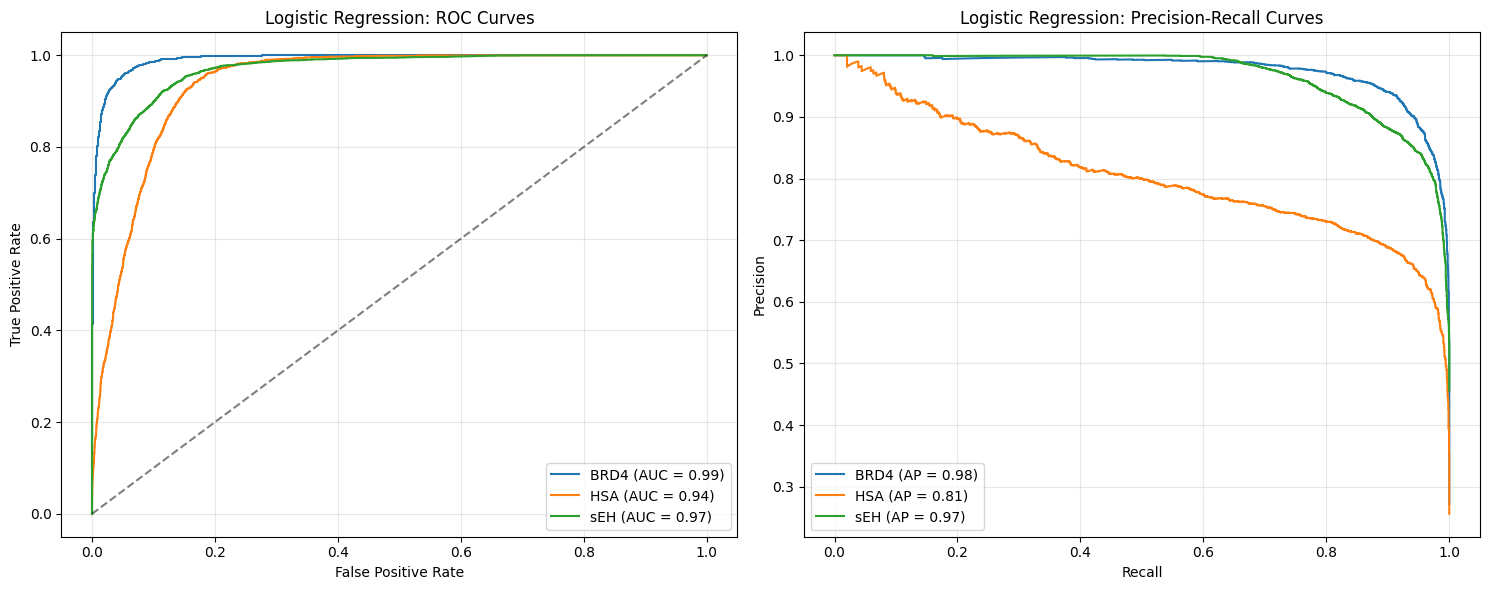


Results for: LightGBM
Macro AUROC: 0.9652
Macro AUPRC: 0.9148


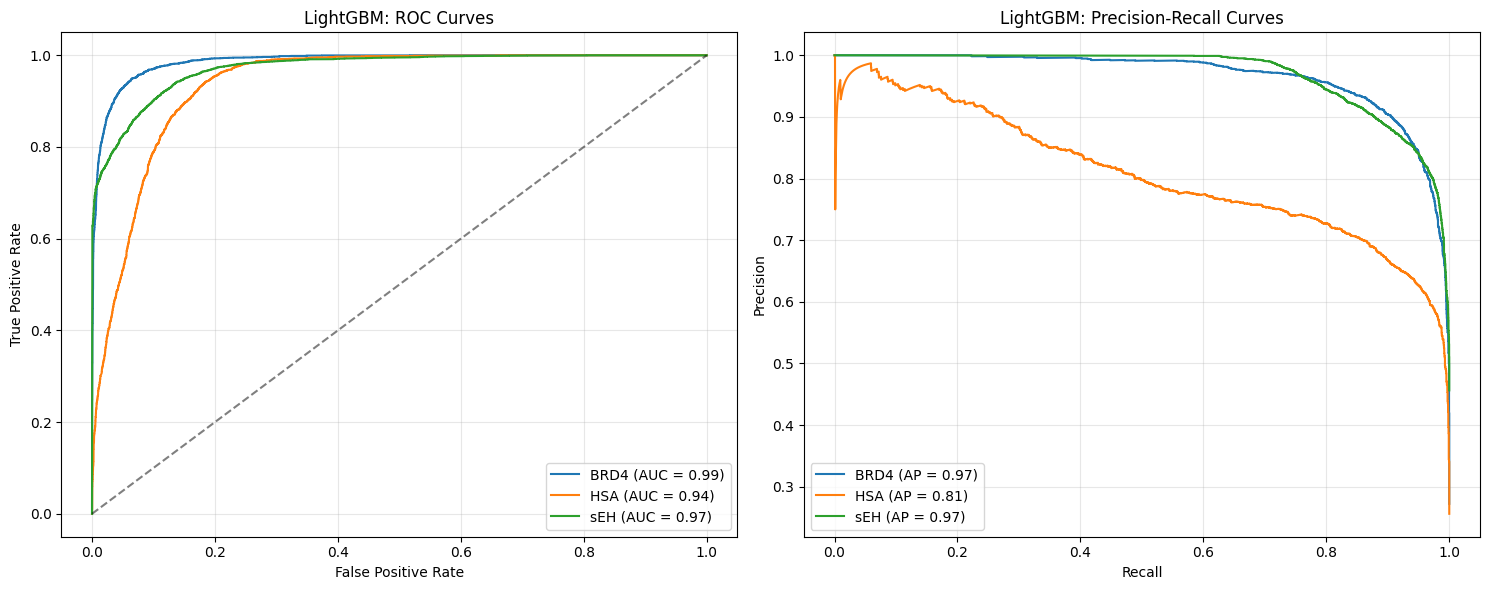

In [6]:
# ==========================================
# 6. Evaluation & Plotting
# ==========================================
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve, precision_recall_curve
import numpy as np

def evaluate_and_plot(y_true, y_pred, model_name, labels):
    """
    Calculates metrics and generates ROC and PR curves for multi-label classification.
    """
    # Ensure inputs are numpy arrays
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    
    # 1. Calculate Macro Metrics
    try:
        auroc = roc_auc_score(y_true, y_pred, average='macro')
    except ValueError:
        auroc = np.nan # Handle cases where a class might be missing in test set
        print(f"Warning: Macro AUROC could not be calculated for {model_name} (likely single class in test set).")
        
    try:
        auprc = average_precision_score(y_true, y_pred, average='macro')
    except ValueError:
        auprc = np.nan
        print(f"Warning: Macro AUPRC could not be calculated for {model_name}.")

    print(f"\n" + "="*40)
    print(f"Results for: {model_name}")
    print(f"="*40)
    print(f"Macro AUROC: {auroc:.4f}")
    print(f"Macro AUPRC: {auprc:.4f}")
    
    # 2. Plotting
    fig, axes = plt.subplots(1, 2, figsize=(15, 6))
    
    # --- ROC Curve ---
    for i, label in enumerate(labels):
        # Check if valid (needs both positive and negative samples in y_true)
        if len(np.unique(y_true[:, i])) > 1:
            fpr, tpr, _ = roc_curve(y_true[:, i], y_pred[:, i])
            score = roc_auc_score(y_true[:, i], y_pred[:, i])
            axes[0].plot(fpr, tpr, label=f'{label} (AUC = {score:.2f})')
        else:
             axes[0].plot([], [], label=f'{label} (N/A - Single Class)')
             
    axes[0].plot([0, 1], [0, 1], 'k--', alpha=0.5)
    axes[0].set_title(f'{model_name}: ROC Curves')
    axes[0].set_xlabel('False Positive Rate')
    axes[0].set_ylabel('True Positive Rate')
    axes[0].legend(loc='lower right')
    axes[0].grid(True, alpha=0.3)
    
    # --- Precision-Recall Curve ---
    for i, label in enumerate(labels):
        if len(np.unique(y_true[:, i])) > 1:
            precision, recall, _ = precision_recall_curve(y_true[:, i], y_pred[:, i])
            score = average_precision_score(y_true[:, i], y_pred[:, i])
            axes[1].plot(recall, precision, label=f'{label} (AP = {score:.2f})')
        else:
            axes[1].plot([], [], label=f'{label} (N/A)')

    axes[1].set_title(f'{model_name}: Precision-Recall Curves')
    axes[1].set_xlabel('Recall')
    axes[1].set_ylabel('Precision')
    axes[1].legend(loc='lower left')
    axes[1].grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()

# Run evaluation for all models stored in 'results'
if 'results' in locals() and results:
    for model_name, preds in results.items():
        evaluate_and_plot(y_test, preds, model_name, CFG.LABEL_COLS)
else:
    print("No results dictionary found. Please run Cell 5 (Model Training) first.")


=== Model Performance Table ===


,model,f1_macro,f1_BRD4,f1_HSA,f1_sEH,roc_auc_BRD4,roc_auc_HSA,roc_auc_sEH,mAP_macro
0,Logistic Regression,0.862047,0.915379,0.780930,0.889831,0.991341,0.939005,0.970614,0.916604
1,LightGBM,0.849020,0.891836,0.762976,0.892248,0.986523,0.937632,0.971591,0.914814


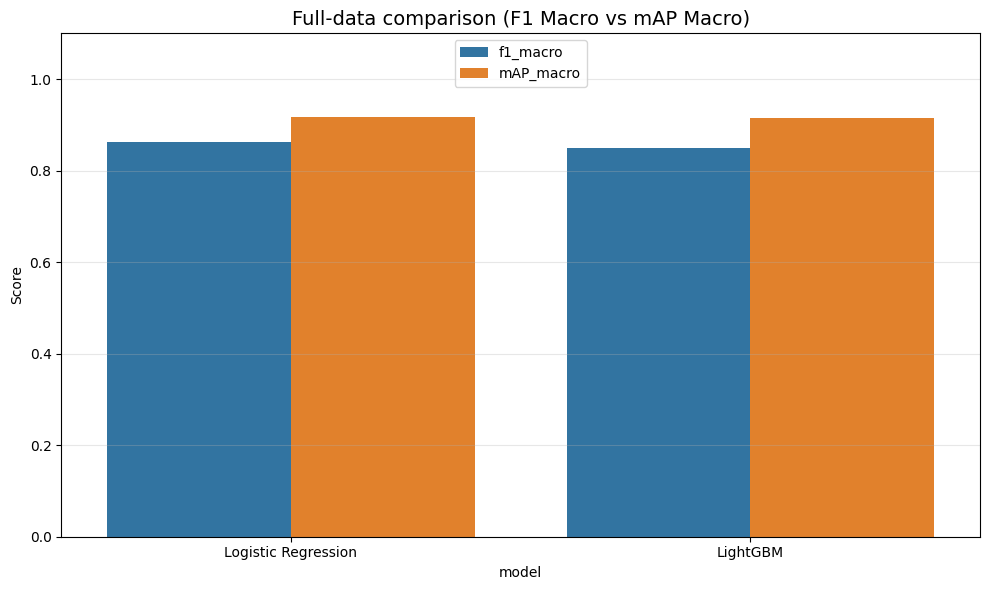

In [8]:
# ==========================================
# 6. Evaluation & Plotting (Matches Image Format)
# ==========================================
from sklearn.metrics import f1_score, roc_auc_score, average_precision_score
import seaborn as sns

def get_detailed_metrics(y_true, y_pred_probs, model_name, labels, threshold=0.5):
    """
    Generates a row of metrics matching the requested table format:
    [model, f1_macro, f1_BRD4, f1_HSA, f1_sEH, roc_auc_BRD4, ..., mAP_macro]
    """
    # Convert probabilities to binary predictions
    y_pred_bin = (y_pred_probs > threshold).astype(int)
    
    # 1. F1 Scores
    f1_macro = f1_score(y_true, y_pred_bin, average='macro', zero_division=0)
    f1_per_class = f1_score(y_true, y_pred_bin, average=None, zero_division=0)
    
    # 2. ROC AUC (Per Class)
    try:
        roc_per_class = roc_auc_score(y_true, y_pred_probs, average=None)
    except ValueError:
        # Handle cases where a class might be missing in test set
        roc_per_class = [np.nan] * len(labels)

    # 3. mAP (Mean Average Precision)
    map_macro = average_precision_score(y_true, y_pred_probs, average='macro')

    # Build the Dictionary Row
    row = {'model': model_name, 'f1_macro': f1_macro, 'mAP_macro': map_macro}
    
    # Add per-class F1 and ROC
    for i, label in enumerate(labels):
        row[f'f1_{label}'] = f1_per_class[i]
        row[f'roc_auc_{label}'] = roc_per_class[i]
        
    return row

# --- A. Generate the Metrics Table ---
metrics_rows = []

if 'results' in locals() and results:
    for model_name, preds in results.items():
        # Calculate metrics for each model
        row = get_detailed_metrics(y_test, preds, model_name, CFG.LABEL_COLS)
        metrics_rows.append(row)
else:
    print("No results found. Run training (Section 5) first.")

# Create and Display DataFrame
metrics_df = pd.DataFrame(metrics_rows)

# Reorder columns to match the image explicitly
cols_order = ['model', 'f1_macro'] + \
             [f'f1_{l}' for l in CFG.LABEL_COLS] + \
             [f'roc_auc_{l}' for l in CFG.LABEL_COLS] + \
             ['mAP_macro']

metrics_df = metrics_df[cols_order]

print("\n=== Model Performance Table ===")
display(metrics_df.style.background_gradient(cmap='Blues', subset=metrics_df.columns[1:]))


# --- B. Generate the Bar Chart Comparison ---
def plot_comparison(df):
    """
    Plots F1_macro and mAP_macro side-by-side for all models.
    """
    # Melt dataframe for seaborn plotting
    plot_df = df.melt(id_vars='model', 
                      value_vars=['f1_macro', 'mAP_macro'], 
                      var_name='Metric', value_name='Score')

    plt.figure(figsize=(10, 6))
    sns.barplot(data=plot_df, x='model', y='Score', hue='Metric', palette=['tab:blue', 'tab:orange'])
    
    plt.title('Full-data comparison (F1 Macro vs mAP Macro)', fontsize=14)
    plt.ylim(0, 1.1)
    plt.grid(axis='y', alpha=0.3)
    plt.legend(loc='upper center')
    plt.tight_layout()
    plt.show()

plot_comparison(metrics_df)


Computing t-SNE for a subset of 2000 molecules...


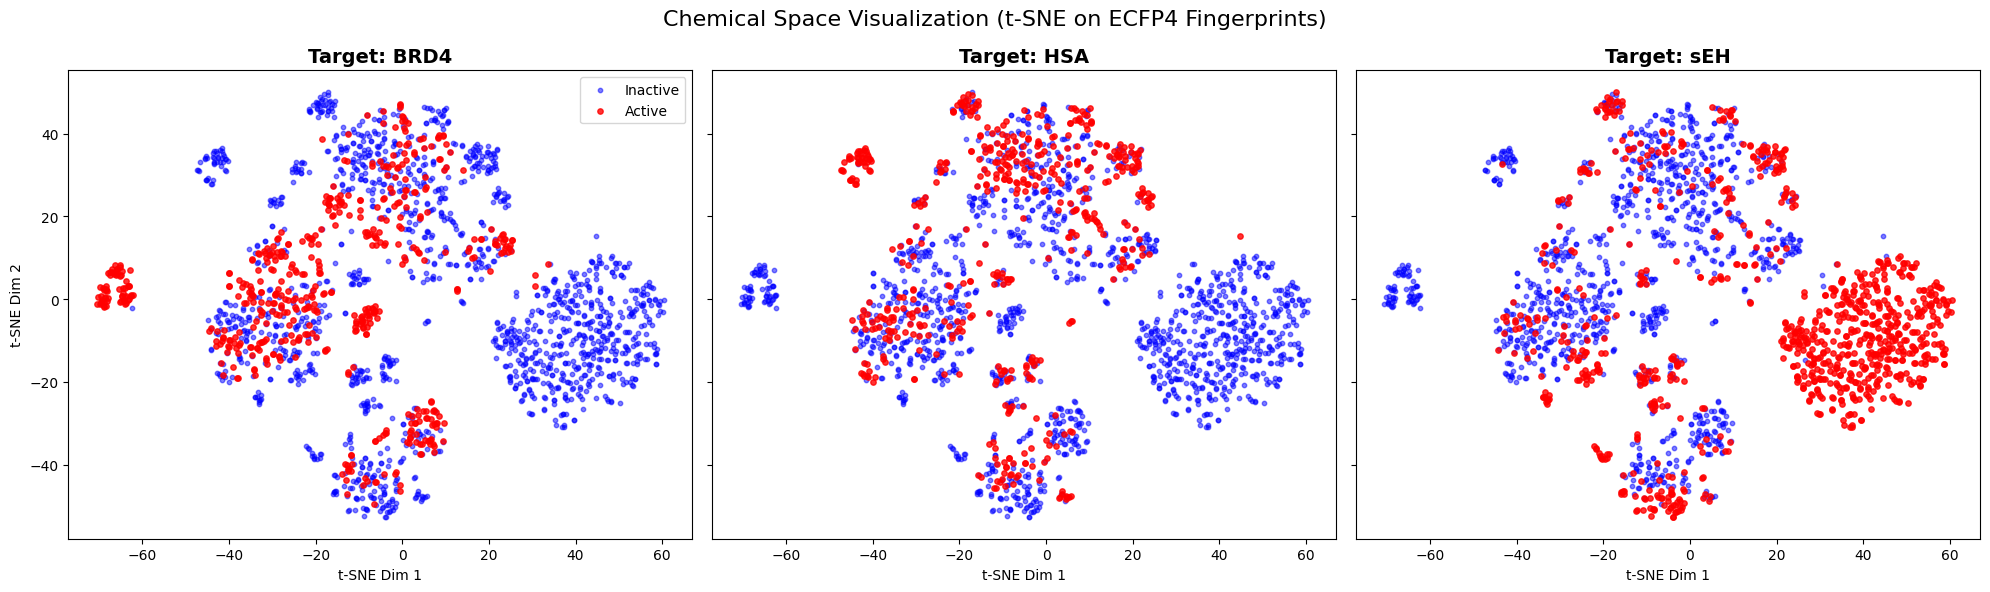

In [10]:
# ==========================================
# 7. Chemical Space Visualization (t-SNE)
# ==========================================
from sklearn.manifold import TSNE
from sklearn.decomposition import TruncatedSVD

def plot_tsne_embeddings(X_sparse, y_labels, target_names, max_samples=2000):
    """
    1. Reduces sparse fingerprints with SVD (LSA).
    2. Computes t-SNE embeddings.
    3. Plots 3 subplots (one for each protein target).
    """
    print(f"\nComputing t-SNE for a subset of {max_samples} molecules...")
    
    # 1. Sampling (t-SNE is too slow for full dataset)
    n_samples = min(X_sparse.shape[0], max_samples)
    indices = np.random.choice(X_sparse.shape[0], n_samples, replace=False)
    
    X_sub = X_sparse[indices]
    y_sub = y_labels[indices]
    
    # 2. Dimensionality Reduction (SVD -> t-SNE)
    # Using TruncatedSVD first is standard practice for sparse ECFP fingerprints
    svd = TruncatedSVD(n_components=50, random_state=42)
    X_pca = svd.fit_transform(X_sub)
    
    tsne = TSNE(n_components=2, perplexity=30, random_state=42, n_jobs=-1)
    X_embedded = tsne.fit_transform(X_pca)
    
    # 3. Plotting
    fig, axes = plt.subplots(1, 3, figsize=(20, 6), sharey=True, sharex=True)
    
    # Loop through each target (BRD4, HSA, sEH)
    for i, target in enumerate(target_names):
        ax = axes[i]
        
        # Color by Active (1) vs Inactive (0)
        # 0 = Blue (Inactive), 1 = Red (Active)
        actives = y_sub[:, i] == 1
        inactives = y_sub[:, i] == 0
        
        # Plot inactives first (background)
        ax.scatter(X_embedded[inactives, 0], X_embedded[inactives, 1], 
                   c='blue', label='Inactive', alpha=0.5, s=10)
        
        # Plot actives on top
        ax.scatter(X_embedded[actives, 0], X_embedded[actives, 1], 
                   c='red', label='Active', alpha=0.8, s=15)
        
        ax.set_title(f"Target: {target}", fontsize=14, fontweight='bold')
        ax.set_xlabel("t-SNE Dim 1")
        if i == 0: ax.set_ylabel("t-SNE Dim 2")
        
        # Add legend only to the first plot to avoid clutter
        if i == 0: ax.legend()

    plt.suptitle("Chemical Space Visualization (t-SNE on ECFP4 Fingerprints)", fontsize=16)
    plt.tight_layout()
    plt.show()

# Run the visualization on the Test Set
plot_tsne_embeddings(X_test, y_test, CFG.LABEL_COLS)